In [3]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\SPR')
import Treat_SPR_func as Treat_SPR_func
importlib.reload(Treat_SPR_func)
from Treat_SPR_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [4]:
path_simu = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND - dimeres\SPR'

simu_shape = 'cylinder'
diameter = 'Single ND'
sample_name = 'Silice thick'

dir_root = '\\'.join((path_simu, sample_name, diameter, simu_shape))


Fname_list = ['D_120_nm_gap_20_nm_polar_0 - part2']
Fname_list = ['e_40nm_Dmin_80nm_Dmax_240nm - spectra']
#fname_raw = 'Sapphire - raw simu results'
Spectra_data = get_raw_size_sweep_data_Nathan(dir_root, Fname_list)

fit_Lorentz_all_data(Spectra_data, w_guess=0.1)

#dir_to_save = dir_root + '\Treated_SPR'


#fname = 'Treated_simulations'
#save_treated_simulation_data(Spectra_data, dir_to_save, fname)

Total size of raw data : 549
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------


 res fit : [np.float64(2.178638261738625), np.float64(0.22703786818890379), np.float64(10471.031289807548)]
 res fit : [np.float64(2.0819489945006913), np.float64(0.2512929061793208), np.float64(22181.62584098044)]
 res fit : [np.float64(1.976013426918813), np.float64(0.292727186315743), np.float64(39464.73152363298)]
 res fit : [np.float64(1.8678941408264718), np.float64(0.3353733489309486), np.float64(60126.16155976631)]
 res fit : [np.float64(1.7660704066843194), np.float64(0.387485659008429), np.float64(84233.96240563951)]
 res fit : [np.float64(1.6700550548791895), np.float64(0.4417619723379587), np.float64(111572.46596841849)]
 res fit : [np.float64(1.5781098812028669), np.float64(0.4963726908450464), np.float64(142567.85179876751)]
 res fit : [np.float64(1.4927376117311135), np.float64(0.5729949088494044), np.float64(184308.71416396057)]
 res fit : [np.float64(1.4055866333937463), np.float64(0.6595664314882561), np.float64(237000.23046333893)]


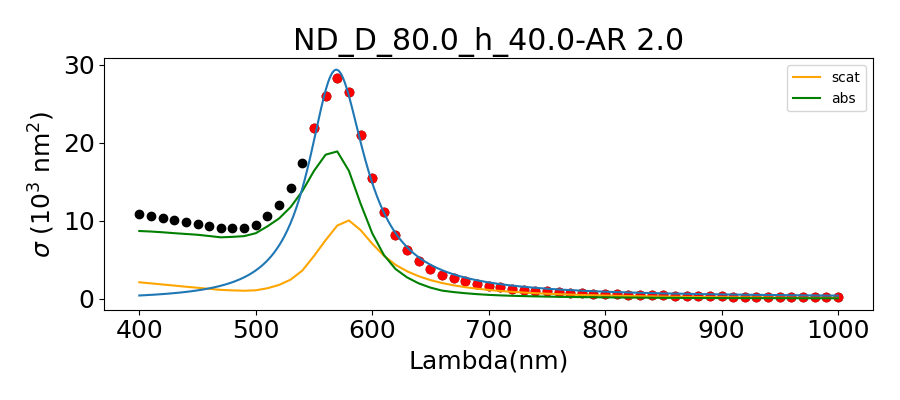

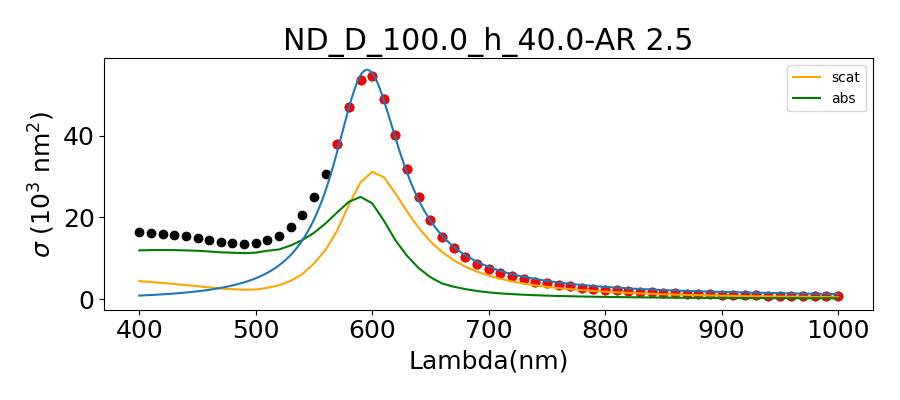

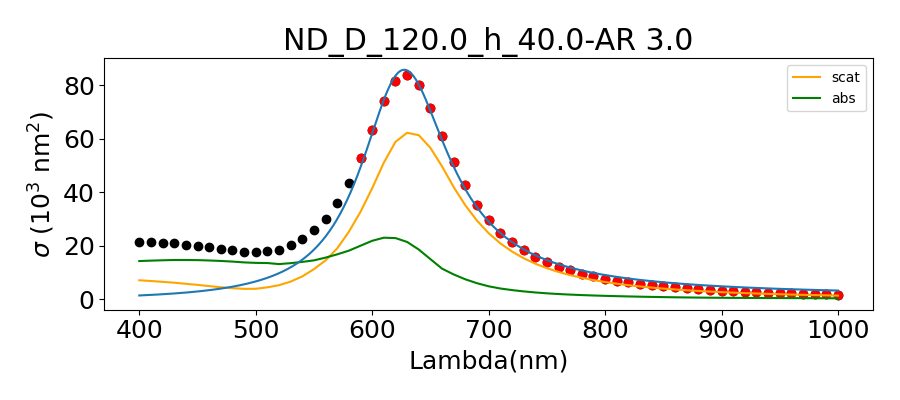

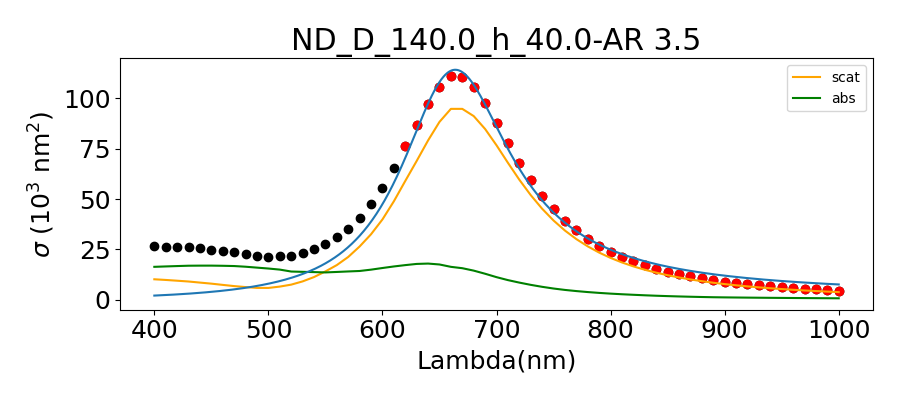

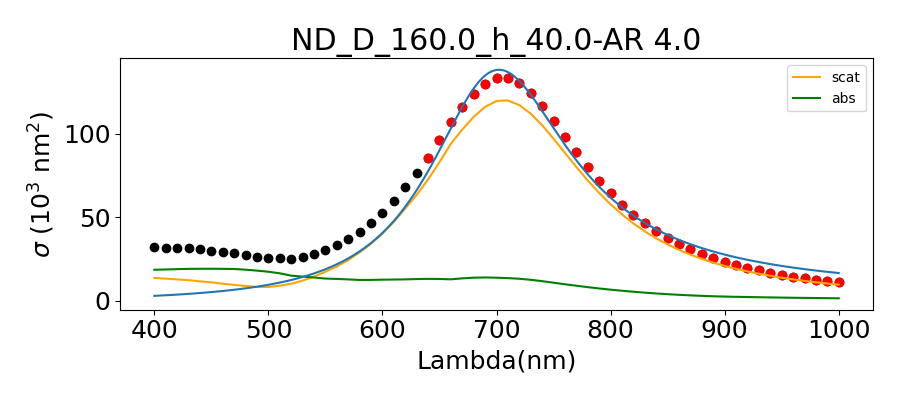

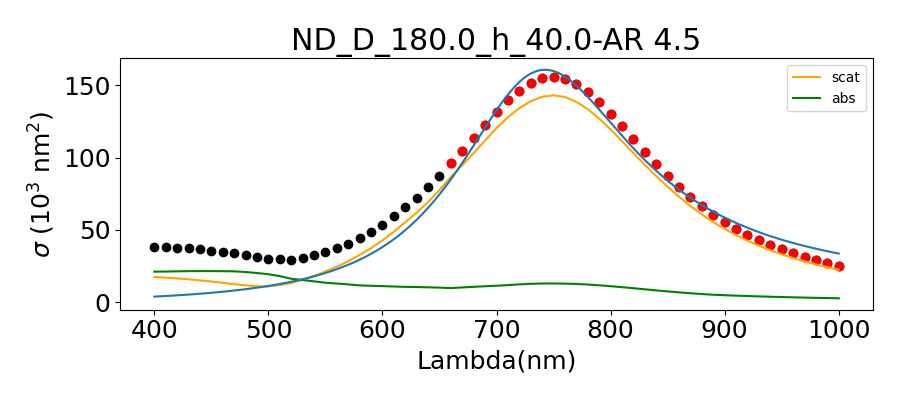

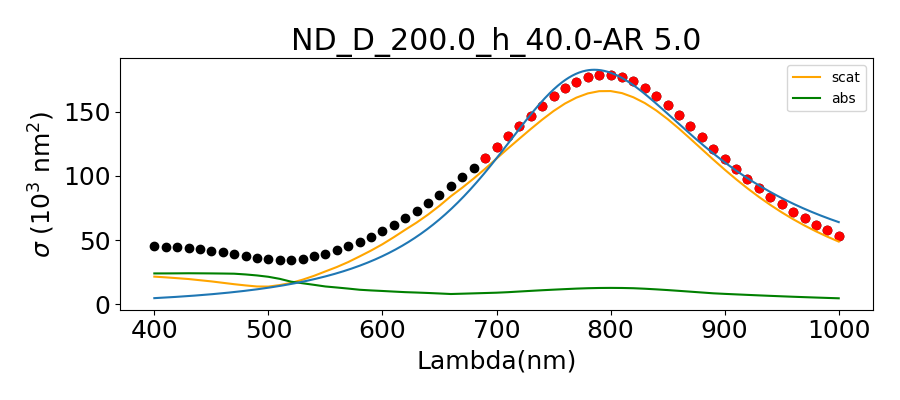

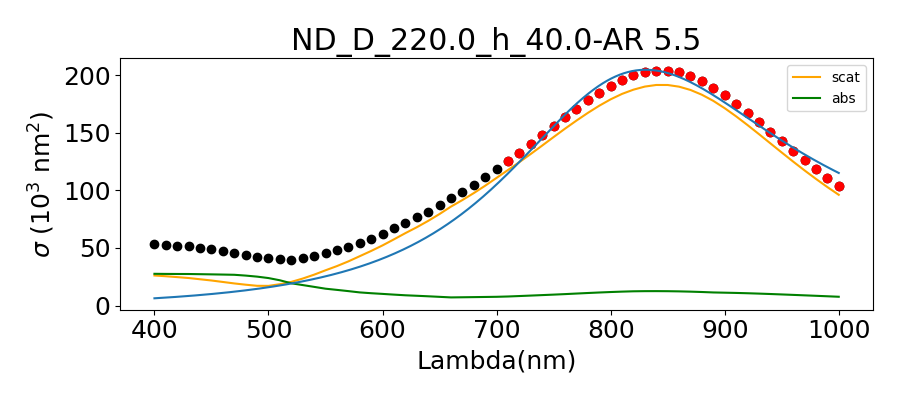

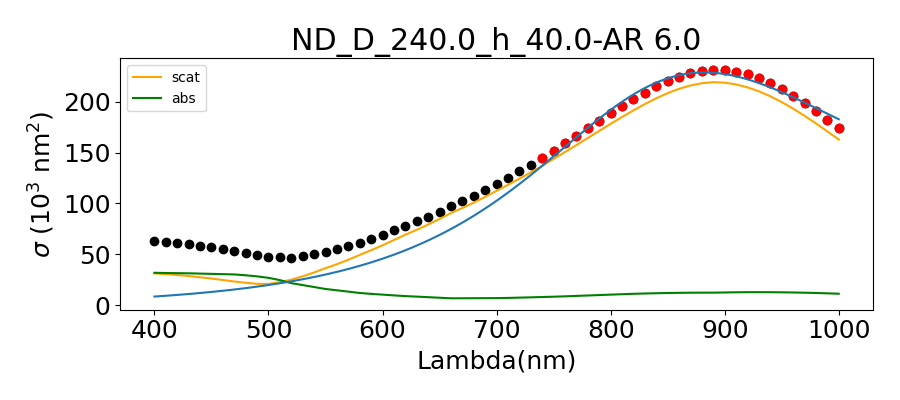

In [5]:
Lambda = np.linspace(400, 1000, 1000)
E = 1240/Lambda

if 1 :
        
    for key in Spectra_data :
        
        spectra = Spectra_data[key]

        
            
        fig, ax = plt.subplots(figsize = (9,4))

        ax.scatter(spectra['Lambda'], spectra['Sigma_ext']*1e-3, color='black')
        ax.plot(spectra['Lambda'], spectra['Sigma_scat']*1e-3, color='orange', label='scat')
        ax.plot(spectra['Lambda'], spectra['Sigma_abs']*1e-3, color='green', label='abs')




        ax.plot(1240/E, Lorentz_no_offset(E, *spectra['res_fit']['coeffs'])*1e-3)
        ax.scatter(spectra['Lambda'][spectra['res_fit']['idx']], spectra['Sigma_ext'][spectra['res_fit']['idx']]*1e-3, color='red')


        print(' res fit : {}'.format([*spectra['res_fit']['coeffs']]))

        ax.set_title(key + '-' + 'AR '+ str(spectra['AR']))
        ax.set_xlabel('Lambda(nm)')
        ax.set_ylabel(r'$\sigma$ ($10^3$ nm$^2$)')
        plt.legend(fontsize=10)
        plt.tight_layout()